## 1. Project Overview

This project analyzes a synthetic B2B financial dataset to evaluate business performance through revenue, cost, profitability, customer, and product analysis. The goal is to identify key business trends, understand profit margins, and uncover opportunities for improving financial performance.

The analysis uses Python, SQL, and Power BI to explore the data, calculate key performance indicators (KPIs), and build an interactive financial performance dashboard.


## 2. Import Libraries

This section imports the Python libraries required for data analysis.

In [237]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## 3. Load Dataset

Load the raw B2B financial dataset into a Pandas DataFrame for analysis.

In [238]:
df = pd.read_csv("../data/raw/b2b_invoices.csv")
df.head()

,order_date,invoice_no,customer_id,customer,product_id,product,category,segment,quantity,unit_cost,unit_price,revenue,cost,margin,ship_date
0,2026-10-27,1,2,Spotless Suppliers of Lakedale,8,Dazzling 2-Ply Toilet Paper,paper & tissue,segA,130,19,21.85,2840.50,2470,370.50,2026-10-28
1,2026-10-27,1,2,Spotless Suppliers of Lakedale,12,Bright 2-Ply Toilet Paper,paper & tissue,segA,27,49,66.15,1786.05,1323,463.05,2026-10-28
2,2026-10-27,1,2,Spotless Suppliers of Lakedale,14,Polished Bathroom Tissue,paper & tissue,segA,13,46,65.78,855.14,598,257.14,2026-10-28
3,2026-10-27,1,2,Spotless Suppliers of Lakedale,22,Sparkling Roll Paper Towels,paper & tissue,segA,6,24,35.76,214.56,144,70.56,2026-10-28
4,2026-10-27,1,2,Spotless Suppliers of Lakedale,58,Polished Disinfectant Wipes,cleaning supplies,segD,1,34,64.26,64.26,34,30.26,2026-10-28


## 4. Initial Data Inspection

Inspect the dataset structure, dimensions, column names, data types, and sample records to understand the data before analysis.

In [239]:
# Display first 5 rows
display(df.head())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()

# Generate descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe())

# Check data types
print("\nColumn Data Types:")
display(df.dtypes)

,order_date,invoice_no,customer_id,customer,product_id,product,category,segment,quantity,unit_cost,unit_price,revenue,cost,margin,ship_date
0,2026-10-27,1,2,Spotless Suppliers of Lakedale,8,Dazzling 2-Ply Toilet Paper,paper & tissue,segA,130,19,21.85,2840.50,2470,370.50,2026-10-28
1,2026-10-27,1,2,Spotless Suppliers of Lakedale,12,Bright 2-Ply Toilet Paper,paper & tissue,segA,27,49,66.15,1786.05,1323,463.05,2026-10-28
2,2026-10-27,1,2,Spotless Suppliers of Lakedale,14,Polished Bathroom Tissue,paper & tissue,segA,13,46,65.78,855.14,598,257.14,2026-10-28
3,2026-10-27,1,2,Spotless Suppliers of Lakedale,22,Sparkling Roll Paper Towels,paper & tissue,segA,6,24,35.76,214.56,144,70.56,2026-10-28
4,2026-10-27,1,2,Spotless Suppliers of Lakedale,58,Polished Disinfectant Wipes,cleaning supplies,segD,1,34,64.26,64.26,34,30.26,2026-10-28


Dataset Shape: (6000, 15)

Column Names:
['order_date', 'invoice_no', 'customer_id', 'customer', 'product_id', 'product', 'category', 'segment', 'quantity', 'unit_cost', 'unit_price', 'revenue', 'cost', 'margin', 'ship_date']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   order_date   6000 non-null   object 
 1   invoice_no   6000 non-null   int64  
 2   customer_id  6000 non-null   int64  
 3   customer     6000 non-null   object 
 4   product_id   6000 non-null   int64  
 5   product      6000 non-null   object 
 6   category     6000 non-null   object 
 7   segment      6000 non-null   object 
 8   quantity     6000 non-null   int64  
 9   unit_cost    6000 non-null   int64  
 10  unit_price   6000 non-null   float64
 11  revenue      6000 non-null   float64
 12  cost         6000 non-null   int64  
 13  margin    

,invoice_no,customer_id,product_id,quantity,unit_cost,unit_price,revenue,cost,margin
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,278.541667,142.576833,61.560667,11.976500,32.526167,51.660995,580.016932,407.907333,172.109598
std,157.066496,85.304485,33.861243,48.610562,13.702492,21.797731,2419.711790,1810.294221,642.840775
min,1.000000,1.000000,1.000000,1.000000,5.000000,7.500000,8.500000,5.000000,3.500000
25%,144.000000,64.000000,33.000000,1.000000,21.000000,35.355000,52.500000,32.000000,20.540000
50%,282.000000,144.000000,63.000000,2.000000,33.000000,50.205000,105.525000,66.000000,39.000000
75%,410.000000,214.000000,90.000000,6.000000,43.000000,65.360000,320.000000,208.000000,108.800000
max,550.000000,299.000000,120.000000,1175.000000,58.000000,120.270000,77832.000000,54050.000000,23782.000000



Column Data Types:


order_date      object
invoice_no       int64
customer_id      int64
customer        object
product_id       int64
product         object
category        object
segment         object
quantity         int64
unit_cost        int64
unit_price     float64
revenue        float64
cost             int64
margin         float64
ship_date       object
dtype: object

## 5. Data Quality Checks

Perform data quality checks to identify missing values, duplicate records, and potential inconsistencies in the dataset before proceeding with data cleaning and analysis.

In [240]:
# Check missing values
print("Missing Values:")
display(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check dataset dimensions
print("\nDataset Shape:", df.shape)

Missing Values:


order_date     0
invoice_no     0
customer_id    0
customer       0
product_id     0
product        0
category       0
segment        0
quantity       0
unit_cost      0
unit_price     0
revenue        0
cost           0
margin         0
ship_date      0
dtype: int64


Duplicate Rows: 0

Dataset Shape: (6000, 15)


In [241]:
# Check whether revenue = quantity * unit_price
print("Revenue Validation:",
      ((df["quantity"] * df["unit_price"] - df["revenue"]).abs() < 0.01).all())

# Check whether cost = quantity * unit_cost
print("Cost Validation:",
      ((df["quantity"] * df["unit_cost"] - df["cost"]).abs() < 0.01).all())

# Check whether margin = revenue - cost
print("Margin Validation:",
      ((df["revenue"] - df["cost"] - df["margin"]).abs() < 0.01).all())

# Check invalid shipping dates
print("Invalid Shipping Dates:",
      (df["ship_date"] < df["order_date"]).sum())

Revenue Validation: True
Cost Validation: True
Margin Validation: True
Invalid Shipping Dates: 0


In [242]:
df["category"].unique()

array(['paper & tissue', 'cleaning supplies', 'office products',
       'breakroom supplies', 'copy paper'], dtype=object)

In [243]:
category_revenue = df.groupby("category")["revenue"].sum()

category_revenue

category
breakroom supplies    262627.03
cleaning supplies     860396.47
copy paper            858036.72
office products       572236.50
paper & tissue        926804.87
Name: revenue, dtype: float64

In [244]:
category_revenue.sort_values(ascending=False)

category
paper & tissue        926804.87
cleaning supplies     860396.47
copy paper            858036.72
office products       572236.50
breakroom supplies    262627.03
Name: revenue, dtype: float64

In [245]:
total_revenue = df["revenue"].sum()

In [246]:
category_revenue_pct = (category_revenue / total_revenue) * 100

category_revenue_pct.round(2)

category
breakroom supplies     7.55
cleaning supplies     24.72
copy paper            24.66
office products       16.44
paper & tissue        26.63
Name: revenue, dtype: float64

In [247]:
print(category_revenue)
print(total_revenue)

category
breakroom supplies    262627.03
cleaning supplies     860396.47
copy paper            858036.72
office products       572236.50
paper & tissue        926804.87
Name: revenue, dtype: float64
3480101.59


In [248]:
category_profit = df.groupby("category")["margin"].sum()

category_profit.sort_values(ascending=False)

category
cleaning supplies     323713.47
copy paper            230221.72
paper & tissue        221022.87
office products       150930.50
breakroom supplies    106769.03
Name: margin, dtype: float64

In [249]:
category_margin_pct = (
    df.groupby("category")["margin"].sum()
    / df.groupby("category")["revenue"].sum()
) * 100

category_margin_pct.sort_values(ascending=False).round(2)

category
breakroom supplies    40.65
cleaning supplies     37.62
copy paper            26.83
office products       26.38
paper & tissue        23.85
dtype: float64

In [250]:
segment_analysis = df.groupby("segment").agg({
    "revenue": "sum",
    "cost": "sum",
    "margin": "sum"
})

segment_analysis

,revenue,cost,margin
segment,,,
segA,3178602.69,2243471,935131.69
segB,119979.70,77930,42049.70
segC,166116.30,117504,48612.30
segD,15402.90,8539,6863.90


In [251]:
top_customers = (
    df.groupby("customer")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

top_customers

customer
Sleek Maintainers of Bayfield        414407.58
Gleaming Sanitizers of Canyonport    253853.69
Radiant Sanitizers of Cedarfield     212428.18
Bright Suppliers of Cedarridge       196567.51
Radiant Sanitizers of Gardenhaven    138774.72
Name: revenue, dtype: float64

## Key Business Insights

1. Breakroom supplies has the highest profit margin at 40.65%.
2. Cleaning supplies generates the highest total profit.
3. Paper & tissue generates the highest category revenue but has the lowest profit margin.
4. Segment A contributes the majority of total revenue and profit.
5. Segment D has the highest profit margin at 44.56%.
6. Sleek Maintainers of Bayfield is the highest revenue-generating customer.

In [252]:
df.to_csv("../data/processed/financial_data_cleaned.csv", index=False)

In [253]:
import os

os.path.exists("../data/processed/financial_data_cleaned.csv")

True

## Additional Data Quality Checks
### 1. Numerical Value Validation

In [254]:
df[["quantity", "unit_cost", "unit_price",
    "revenue", "cost", "margin"]].describe()

,quantity,unit_cost,unit_price,revenue,cost,margin
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,11.976500,32.526167,51.660995,580.016932,407.907333,172.109598
std,48.610562,13.702492,21.797731,2419.711790,1810.294221,642.840775
min,1.000000,5.000000,7.500000,8.500000,5.000000,3.500000
25%,1.000000,21.000000,35.355000,52.500000,32.000000,20.540000
50%,2.000000,33.000000,50.205000,105.525000,66.000000,39.000000
75%,6.000000,43.000000,65.360000,320.000000,208.000000,108.800000
max,1175.000000,58.000000,120.270000,77832.000000,54050.000000,23782.000000


In [255]:
df[df["quantity"] > 100][
    ["customer", "product", "quantity", "revenue", "cost", "margin"]
]

,customer,product,quantity,revenue,cost,margin
0,Spotless Suppliers of Lakedale,Dazzling 2-Ply Toilet Paper,130,2840.50,2470,370.50
116,Radiant Sanitizers of Cedarfield,Glossy Glossy Photo Paper,103,8630.37,5871,2759.37
205,Sleek Maintainers of Bayfield,Fresh Recycled Paper,462,13083.84,11088,1995.84
211,Sleek Maintainers of Bayfield,Pristine Disinfectant Wipes,648,44712.00,29808,14904.00
215,Sleek Maintainers of Bayfield,Immaculate Air Freshener,495,25245.00,16830,8415.00
...,...,...,...,...,...,...
5898,Sleek Maintainers of Bayfield,Sparkling Markers,962,30014.40,23088,6926.40
5901,Sleek Maintainers of Bayfield,Dazzling Binder Clips,685,33839.00,26030,7809.00
5910,Sleek Maintainers of Bayfield,Immaculate Coffee Beans,327,8829.00,5886,2943.00
5968,Bright Janitors of Valleyhaven,Spotless Markers,366,11660.76,9882,1778.76


In [256]:
(df["quantity"] > 100).sum()

np.int64(94)

In [257]:
df[df["ship_date"] < df["order_date"]]

,order_date,invoice_no,customer_id,customer,product_id,product,category,segment,quantity,unit_cost,unit_price,revenue,cost,margin,ship_date


In [258]:
df["invoice_no"].duplicated().sum()

np.int64(5452)

In [259]:
df["invoice_no"].value_counts().head(10)

invoice_no
280    25
58     25
122    25
369    25
368    24
380    23
545    23
200    23
442    22
379    22
Name: count, dtype: int64

In [260]:
df["category"].str.strip().nunique()

5

In [261]:
df.duplicated().sum()

np.int64(0)

In [262]:
Q1 = df["quantity"].quantile(0.25)
Q3 = df["quantity"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper limit:", upper_limit)

Q1: 1.0
Q3: 6.0
IQR: 5.0
Upper limit: 13.5


In [263]:
outliers = df[df["quantity"] > upper_limit]

print("Potential outliers:", len(outliers))
print("Percentage:", round((len(outliers) / len(df)) * 100, 2), "%")

Potential outliers: 987
Percentage: 16.45 %


In [264]:
outliers.nlargest(10, "quantity")[
    ["invoice_no", "customer", "product",
     "quantity", "revenue", "cost", "margin"]
]

,invoice_no,customer,product,quantity,revenue,cost,margin
1496,144,Spotless Facilities of Forestridge,Pristine Disinfectant Wipes,1175,77832.00,54050,23782.00
2655,251,Immaculate Suppliers of Bayport,Sleek Facial Tissues,1056,19008.00,15840,3168.00
2603,246,Gleaming Sanitizers of Canyonport,Radiant Energy Drinks,969,7267.50,4845,2422.50
5898,543,Sleek Maintainers of Bayfield,Sparkling Markers,962,30014.40,23088,6926.40
1473,142,Immaculate Suppliers of Bayport,Glossy Pocket Tissues,892,51736.00,44600,7136.00
547,54,Sleek Maintainers of Bayfield,Sparkling Markers,717,22370.40,17208,5162.40
4791,441,Bright Suppliers of Cedarridge,Spotless Pocket Tissues,699,42708.90,32853,9855.90
2248,211,Gleaming Sanitizers of Canyonport,Radiant Glossy Photo Paper,698,46821.84,36296,10525.84
5901,543,Sleek Maintainers of Bayfield,Dazzling Binder Clips,685,33839.00,26030,7809.00
211,22,Sleek Maintainers of Bayfield,Pristine Disinfectant Wipes,648,44712.00,29808,14904.00


In [265]:
df.duplicated(subset=["invoice_no", "product_id"]).sum()

np.int64(0)

In [266]:
df["expected_revenue"] = (
    df["quantity"] * df["unit_price"]
).round(2)

df["expected_cost"] = (
    df["quantity"] * df["unit_cost"]
).round(2)

print("Revenue mismatches:",
      (df["revenue"].round(2) != df["expected_revenue"]).sum())

print("Cost mismatches:",
      (df["cost"].round(2) != df["expected_cost"]).sum())

Revenue mismatches: 0
Cost mismatches: 0


In [267]:
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    print(col, (df[col] != df[col].str.strip()).sum())

order_date 0
customer 0
product 0
category 0
segment 0
ship_date 0


In [268]:
df["category"].value_counts()

category
breakroom supplies    1325
cleaning supplies     1318
paper & tissue        1152
copy paper            1145
office products       1060
Name: count, dtype: int64

In [269]:
df.groupby("customer_id")["customer"].nunique().sort_values(ascending=False).head(10)

customer_id
1      1
202    1
182    1
184    1
186    1
187    1
190    1
193    1
195    1
196    1
Name: customer, dtype: int64

In [270]:
(df.groupby("customer_id")["customer"].nunique() > 1).sum()

np.int64(0)

In [271]:
df.groupby("product_id")["product"].nunique().sort_values(ascending=False).head(10)

product_id
1     1
2     1
89    1
88    1
87    1
86    1
85    1
84    1
83    1
82    1
Name: product, dtype: int64

In [272]:
(df.groupby("product_id")["product"].nunique() > 1).sum()

np.int64(0)

In [273]:
df.groupby("product_id")["category"].nunique().sort_values(ascending=False).head(10)

product_id
1     1
2     1
89    1
88    1
87    1
86    1
85    1
84    1
83    1
82    1
Name: category, dtype: int64

## Additional Data Consistency Checks

The following checks were performed:

1. Checked leading and trailing spaces in text columns. No inconsistencies found.
2. Checked category capitalization. All five categories use consistent lowercase formatting.
3. Verified customer ID-to-customer name mapping. No mismatches found.
4. Verified product ID-to-product name mapping. No mismatches found.
5. Verified product ID-to-category mapping. No mismatches found.

### Conclusion

The dataset passed the planned structural, financial, and text consistency checks. No additional corrections were required during these checks.

The dataset is ready for dashboard development, subject to the limitations of the source data.

In [274]:
(df.groupby("product_id")["category"].nunique() > 1).sum()


np.int64(0)

## 6. Data Cleaning and Validation

Clean and prepare the dataset by checking data types, handling inconsistencies, and validating important financial calculations to ensure data accuracy and reliability before performing exploratory data analysis.


In [275]:
# Convert date columns to datetime format
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

# Verify date data types
print(df[["order_date", "ship_date"]].dtypes)

order_date    datetime64[ns]
ship_date     datetime64[ns]
dtype: object


In [276]:
# Check numerical column data types
df[["quantity", "unit_cost", "unit_price",
    "revenue", "cost", "margin"]].dtypes

quantity        int64
unit_cost       int64
unit_price    float64
revenue       float64
cost            int64
margin        float64
dtype: object

In [277]:
# Check for negative values
numeric_columns = [
    "quantity", "unit_cost", "unit_price",
    "revenue", "cost"
]

(df[numeric_columns] < 0).sum()

quantity      0
unit_cost     0
unit_price    0
revenue       0
cost          0
dtype: int64

In [278]:
# Calculate shipping duration in days
df["shipping_days"] = (
    df["ship_date"] - df["order_date"]
).dt.days

# Display sample results
df[["order_date", "ship_date", "shipping_days"]].head()

,order_date,ship_date,shipping_days
0,2026-10-27,2026-10-28,1
1,2026-10-27,2026-10-28,1
2,2026-10-27,2026-10-28,1
3,2026-10-27,2026-10-28,1
4,2026-10-27,2026-10-28,1


In [279]:
df["shipping_days"].describe()

count    6000.000000
mean        3.232667
std         4.216811
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max        17.000000
Name: shipping_days, dtype: float64

In [280]:
df.shape

(6000, 18)

In [281]:
df.columns.tolist()

['order_date',
 'invoice_no',
 'customer_id',
 'customer',
 'product_id',
 'product',
 'category',
 'segment',
 'quantity',
 'unit_cost',
 'unit_price',
 'revenue',
 'cost',
 'margin',
 'ship_date',
 'expected_revenue',
 'expected_cost',
 'shipping_days']

### Export Cleaned Dataset

Save the cleaned dataset for SQL analysis and Power BI visualization.

In [282]:
df.to_csv("../data/processed/financial_data_cleaned.csv", index=False)

## 7. Exploratory Data Analysis (EDA)

Perform exploratory data analysis to understand the overall financial performance of the business. Analyze key metrics such as total revenue, total cost, total profit, and gross profit margin to identify important business patterns and trends.

In [283]:
# Calculate revenue by category
category_revenue = df.groupby("category")["revenue"].sum().sort_values(ascending=False)

display(category_revenue)

category
paper & tissue        926804.87
cleaning supplies     860396.47
copy paper            858036.72
office products       572236.50
breakroom supplies    262627.03
Name: revenue, dtype: float64

In [284]:
# Calculate total revenue
total_revenue = df["revenue"].sum()

print("Total Revenue:", round(total_revenue, 2))

Total Revenue: 3480101.59


In [285]:
# Calculate total cost
total_cost = df["cost"].sum()

print("Total Cost:", round(total_cost, 2))

Total Cost: 2447444


In [286]:
# Calculate total profit
total_profit = total_revenue - total_cost

print("Total Profit:", round(total_profit, 2))

Total Profit: 1032657.59


In [287]:
# Calculate gross profit margin
gross_margin_pct = (total_profit / total_revenue) * 100

print("Gross Profit Margin:", round(gross_margin_pct, 2), "%")

Gross Profit Margin: 29.67 %


In [288]:
# Overall Business Performance Summary

print("FINANCIAL PERFORMANCE SUMMARY")
print("-" * 35)

print("Total Revenue:", round(total_revenue, 2))
print("Total Cost:", round(total_cost, 2))
print("Total Profit:", round(total_profit, 2))
print("Gross Profit Margin:", round(gross_margin_pct, 2), "%")

FINANCIAL PERFORMANCE SUMMARY
-----------------------------------
Total Revenue: 3480101.59
Total Cost: 2447444
Total Profit: 1032657.59
Gross Profit Margin: 29.67 %


## 8. Category Performance Analysis

Analyze financial performance across product categories by comparing total revenue, total cost, total profit, and profit margins. Identify high-performing and low-performing categories to understand their contribution to overall business performance.

In [289]:
# Identify unique product categories
df["category"].unique()

array(['paper & tissue', 'cleaning supplies', 'office products',
       'breakroom supplies', 'copy paper'], dtype=object)

In [290]:
# Calculate revenue by category
category_revenue = df.groupby("category")["revenue"].sum().sort_values(ascending=False)

display(category_revenue)

category
paper & tissue        926804.87
cleaning supplies     860396.47
copy paper            858036.72
office products       572236.50
breakroom supplies    262627.03
Name: revenue, dtype: float64

In [291]:
# Calculate cost by category
category_cost = df.groupby("category")["cost"].sum().sort_values(ascending=False)

display(category_cost)

category
paper & tissue        705782
copy paper            627815
cleaning supplies     536683
office products       421306
breakroom supplies    155858
Name: cost, dtype: int64

In [292]:
# Calculate profit by category
category_profit = df.groupby("category")["margin"].sum().sort_values(ascending=False)

display(category_profit)

category
cleaning supplies     323713.47
copy paper            230221.72
paper & tissue        221022.87
office products       150930.50
breakroom supplies    106769.03
Name: margin, dtype: float64

In [293]:
# Calculate profit margin by category
category_margin = (category_profit / category_revenue) * 100

category_margin = category_margin.sort_values(ascending=False)

display(category_margin.round(2))

category
breakroom supplies    40.65
cleaning supplies     37.62
copy paper            26.83
office products       26.38
paper & tissue        23.85
dtype: float64

In [294]:
# Category Performance Summary

category_summary = pd.DataFrame({
    "Revenue": category_revenue,
    "Cost": category_cost,
    "Profit": category_profit,
    "Profit Margin (%)": category_margin
})

display(category_summary.round(2))

,Revenue,Cost,Profit,Profit Margin (%)
category,,,,
breakroom supplies,262627.03,155858,106769.03,40.65
cleaning supplies,860396.47,536683,323713.47,37.62
copy paper,858036.72,627815,230221.72,26.83
office products,572236.50,421306,150930.50,26.38
paper & tissue,926804.87,705782,221022.87,23.85


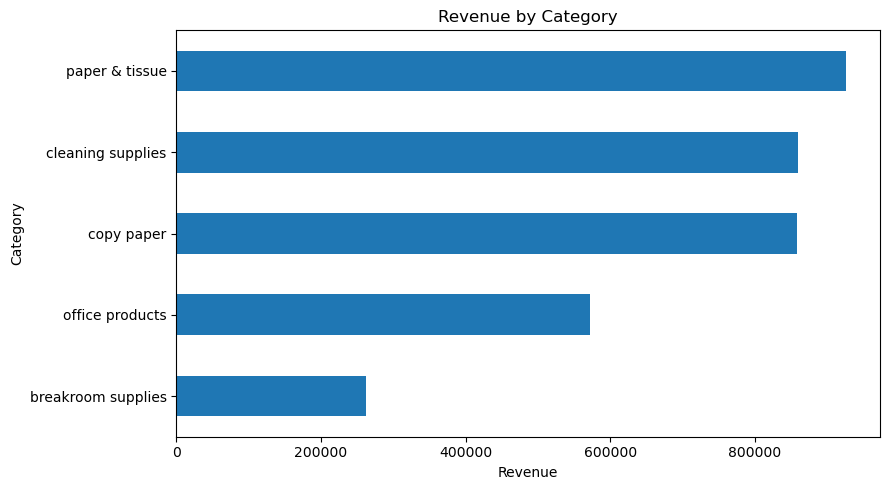

In [295]:
# Revenue by Category

category_revenue.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Revenue by Category"
)

plt.xlabel("Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

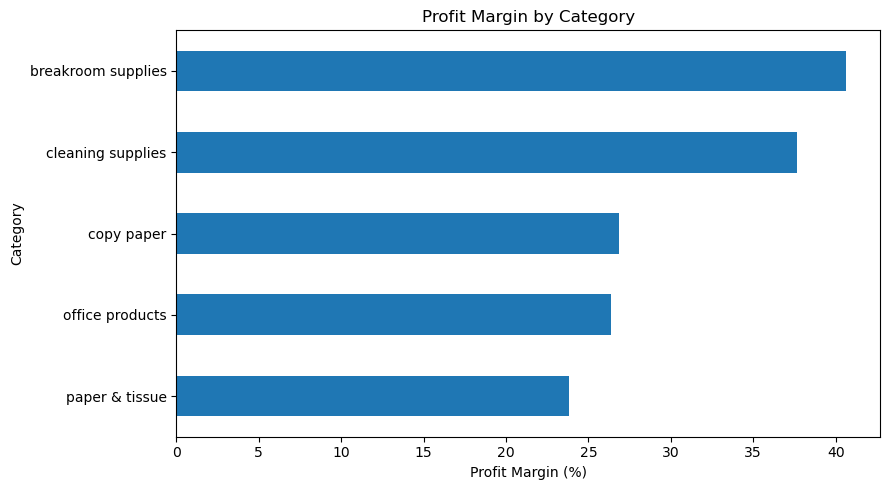

In [296]:
# Profit Margin by Category

category_margin_pct.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Profit Margin by Category"
)

plt.xlabel("Profit Margin (%)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

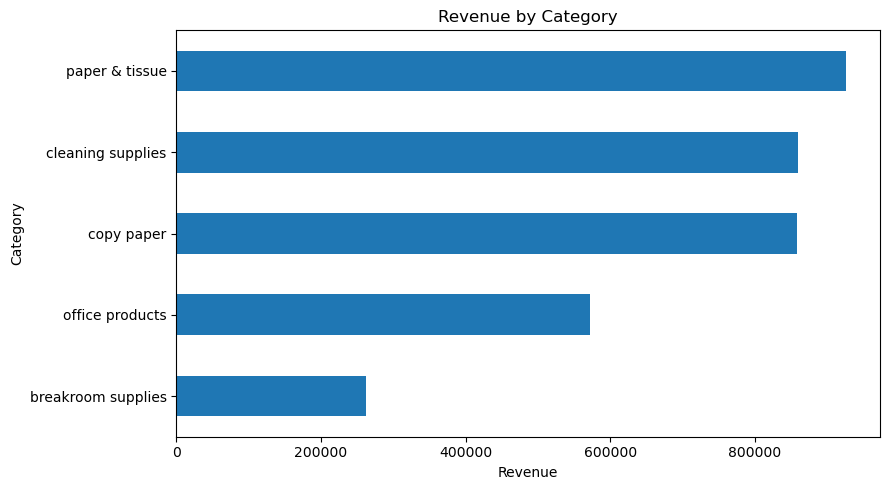

In [297]:
category_revenue.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Revenue by Category"
)

plt.xlabel("Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Key Business Insights – Category Performance

1. Paper & Tissue generates the highest revenue but has the lowest profit margin (23.85%), indicating an opportunity to review its cost structure and pricing strategy.
2. Cleaning Supplies is the strongest category in terms of total profit, contributing 323,713.47.
3. Breakroom Supplies has the highest profit margin (40.65%) despite generating the lowest revenue.
4. Cleaning Supplies and Breakroom Supplies demonstrate stronger profit margins than the other categories.

**Business Recommendation:** Investigate the cost structure of Paper & Tissue, maintain the profitability of Cleaning Supplies, and explore opportunities to increase sales of Breakroom Supplies.

## 9. Customer Segment Analysis

Analyze financial performance across customer segments by comparing revenue, cost, total profit, and profit margins. Identify the most valuable customer segments and evaluate their contribution to overall business profitability.

In [298]:
# Identify unique customer segments
df["segment"].unique()

array(['segA', 'segD', 'segB', 'segC'], dtype=object)

In [299]:
# Calculate revenue by customer segment
segment_revenue = (
    df.groupby("segment")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(segment_revenue)

segment
segA    3178602.69
segC     166116.30
segB     119979.70
segD      15402.90
Name: revenue, dtype: float64

In [300]:
# Calculate cost by customer segment
segment_cost = (
    df.groupby("segment")["cost"]
    .sum()
    .sort_values(ascending=False)
)

display(segment_cost)

segment
segA    2243471
segC     117504
segB      77930
segD       8539
Name: cost, dtype: int64

In [301]:
# Calculate profit by customer segment
segment_profit = (
    df.groupby("segment")["margin"]
    .sum()
    .sort_values(ascending=False)
)

display(segment_profit)

segment
segA    935131.69
segC     48612.30
segB     42049.70
segD      6863.90
Name: margin, dtype: float64

In [302]:
# Calculate profit margin by customer segment
segment_margin = (
    segment_profit / segment_revenue
) * 100

display(segment_margin.round(2))

segment
segA    29.42
segC    29.26
segB    35.05
segD    44.56
dtype: float64

In [303]:
segment_summary = pd.DataFrame({
    "Revenue": segment_revenue,
    "Cost": segment_cost,
    "Profit": segment_profit,
    "Profit Margin (%)": segment_margin
})

display(segment_summary.round(2))

,Revenue,Cost,Profit,Profit Margin (%)
segment,,,,
segA,3178602.69,2243471,935131.69,29.42
segC,166116.30,117504,48612.30,29.26
segB,119979.70,77930,42049.70,35.05
segD,15402.90,8539,6863.90,44.56


### Key Business Insights – Customer Segment Performance

1. Segment A generates the highest revenue (3,178,602.69) and total profit (935,131.69), making it the largest contributor to business performance.
2. Segment D has the highest profit margin (44.56%) despite generating the lowest revenue.
3. Segment B achieves a profit margin of 35.05%, outperforming Segment A and Segment C.
4. Segment C has the lowest profit margin (29.26%), indicating an opportunity to investigate its cost structure.
5. Revenue is heavily concentrated in Segment A, while smaller segments demonstrate opportunities for further profitability analysis.

**Business Recommendation:** Maintain strong relationships with Segment A customers while investigating opportunities to grow Segments B and D. Review Segment C's cost structure to identify potential margin improvements.

## 10. Customer and Product Analysis


Analyze customer and product performance to identify the highest revenue-generating customers and products. Evaluate their contribution to overall business performance and identify key opportunities for improving revenue and profitability.

In [304]:
# Calculate total revenue generated by each customer
customer_revenue = (
    df.groupby("customer")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 customers
top_10_customers = customer_revenue.head(10)

display(top_10_customers)

customer
Sleek Maintainers of Bayfield         414407.58
Gleaming Sanitizers of Canyonport     253853.69
Radiant Sanitizers of Cedarfield      212428.18
Bright Suppliers of Cedarridge        196567.51
Radiant Sanitizers of Gardenhaven     138774.72
Spotless Facilities of Forestridge    127361.05
Sleek Suppliers of Gardendale         110848.69
Immaculate Suppliers of Bayport       103362.46
Fresh Suppliers of Lakehaven           92238.70
Radiant Facilities of Forestdale       87877.08
Name: revenue, dtype: float64

In [305]:
# Calculate total profit generated by each customer
customer_profit = (
    df.groupby("customer")["margin"]
    .sum()
    .sort_values(ascending=False)
)

top_10_customers_profit = customer_profit.head(10)

display(top_10_customers_profit)

customer
Sleek Maintainers of Bayfield         127706.58
Gleaming Sanitizers of Canyonport      81659.69
Radiant Sanitizers of Cedarfield       58074.18
Bright Suppliers of Cedarridge         47176.51
Radiant Sanitizers of Gardenhaven      44623.72
Spotless Facilities of Forestridge     43808.05
Sleek Suppliers of Gardendale          34612.69
Gleaming Suppliers of Forestcrest      30639.36
Bright Janitors of Valleyhaven         24003.51
Glossy Stewards of Cedarville          21837.84
Name: margin, dtype: float64

In [306]:
# Calculate revenue generated by each product
product_revenue = (
    df.groupby("product")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

top_10_products = product_revenue.head(10)

display(top_10_products)

product
Pristine Disinfectant Wipes    223056.76
Radiant Glossy Photo Paper     147721.36
Spotless Pocket Tissues        111372.14
Immaculate Resume Paper        109651.90
Immaculate Air Freshener        95093.58
Dazzling Binder Clips           86659.76
Bright 2-Ply Toilet Paper       85156.61
Sparkling Markers               83244.72
Polished Recycled Paper         74552.81
Glossy Pocket Tissues           74248.00
Name: revenue, dtype: float64

In [307]:
# Calculate profit generated by each product
product_profit = (
    df.groupby("product")["margin"]
    .sum()
    .sort_values(ascending=False)
)

top_10_products_profit = product_profit.head(10)

display(top_10_products_profit)

product
Pristine Disinfectant Wipes    74936.76
Radiant Glossy Photo Paper     34601.36
Immaculate Air Freshener       33111.58
Spotless Pocket Tissues        26866.14
Bright Degreaser               24016.40
Polished Glossy Photo Paper    22088.40
Immaculate Resume Paper        21955.90
Dazzling Binder Clips          21907.76
Sparkling Markers              19428.72
Polished Recycled Paper        18386.81
Name: margin, dtype: float64

In [308]:
customer_summary = pd.DataFrame({
    "Revenue": customer_revenue,
    "Profit": customer_profit
})

display(customer_summary.sort_values(
    by="Revenue", ascending=False
).head(10).round(2))

,Revenue,Profit
customer,,
Sleek Maintainers of Bayfield,414407.58,127706.58
Gleaming Sanitizers of Canyonport,253853.69,81659.69
Radiant Sanitizers of Cedarfield,212428.18,58074.18
Bright Suppliers of Cedarridge,196567.51,47176.51
Radiant Sanitizers of Gardenhaven,138774.72,44623.72
Spotless Facilities of Forestridge,127361.05,43808.05
Sleek Suppliers of Gardendale,110848.69,34612.69
Immaculate Suppliers of Bayport,103362.46,21767.46
Fresh Suppliers of Lakehaven,92238.70,21197.70


In [309]:
product_summary = pd.DataFrame({
    "Revenue": product_revenue,
    "Profit": product_profit
})

display(product_summary.sort_values(
    by="Revenue", ascending=False
).head(10).round(2))

,Revenue,Profit
product,,
Pristine Disinfectant Wipes,223056.76,74936.76
Radiant Glossy Photo Paper,147721.36,34601.36
Spotless Pocket Tissues,111372.14,26866.14
Immaculate Resume Paper,109651.90,21955.90
Immaculate Air Freshener,95093.58,33111.58
Dazzling Binder Clips,86659.76,21907.76
Bright 2-Ply Toilet Paper,85156.61,18369.61
Sparkling Markers,83244.72,19428.72
Polished Recycled Paper,74552.81,18386.81


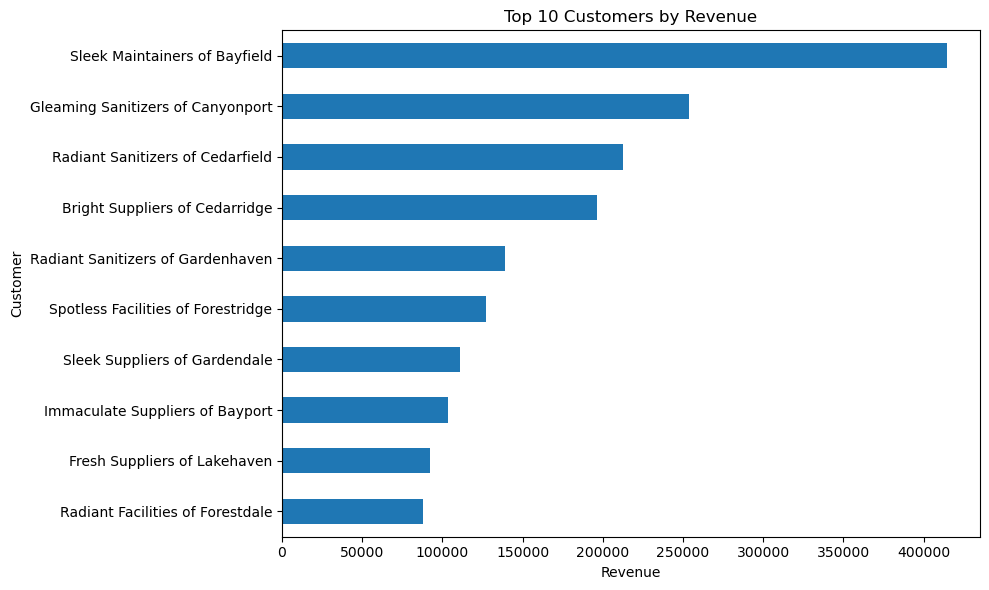

In [310]:


# Top 10 customers by revenue
top_10_customers.sort_values().plot(
    kind="barh", figsize=(10, 6), title="Top 10 Customers by Revenue"
)

plt.xlabel("Revenue")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()

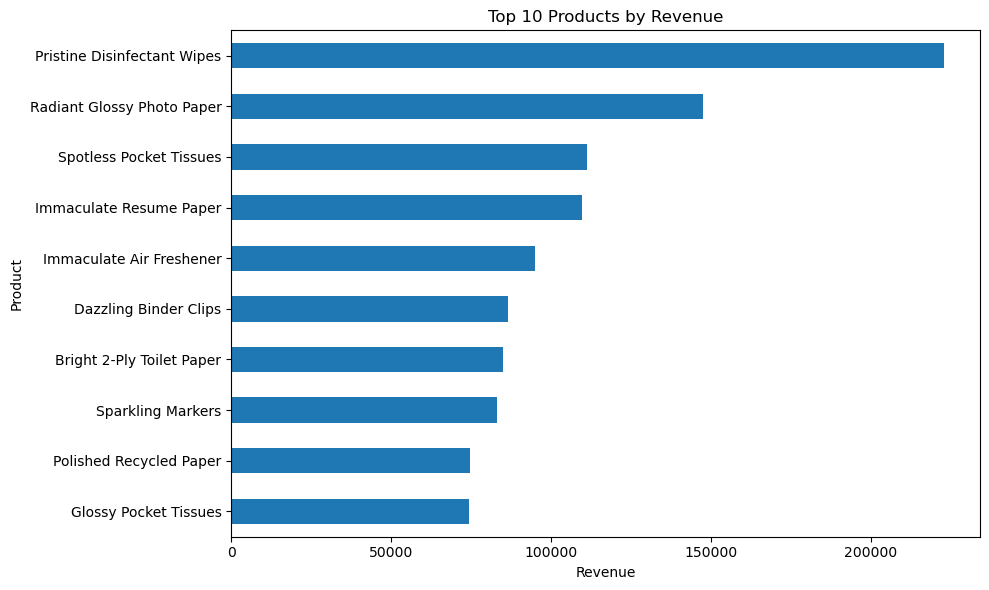

In [311]:
# Top 10 products by revenue
top_10_products.sort_values().plot(
    kind="barh", figsize=(10, 6), title="Top 10 Products by Revenue"
)

plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

### Key Business Insights – Customer and Product Performance

**Customer Performance:**

1. Sleek Maintainers of Bayfield is the highest revenue-generating customer, contributing 414,407.58 in revenue and 127,706.58 in profit.
2. Gleaming Sanitizers of Canyonport ranks second, generating 253,853.69 in revenue and 81,659.69 in profit.
3. Sleek Maintainers of Bayfield also contributes the highest total profit among the customers analyzed.
4. Customer revenue and profit analysis helps identify valuable accounts and opportunities for customer retention.

**Product Performance:**

1. Pristine Disinfectant Wipes is the highest revenue-generating product, contributing 223,056.76 in revenue and 74,936.76 in profit.
2. Radiant Glossy Photo Paper ranks second in revenue, generating 147,721.36.
3. Immaculate Air Freshener generates 95,093.58 in revenue and 33,111.58 in profit.
4. Pristine Disinfectant Wipes also generates the highest total profit among the top 10 products by revenue.

**Business Recommendation:** Focus on retaining high-value customers, strengthening relationships with profitable accounts, and maintaining sales of high-performing products. Investigate opportunities to improve the profitability of products with comparatively lower profit contributions.

## 11. Shipping Performance Analysis

Analyze shipping performance to understand delivery timelines and operational efficiency. Evaluate average shipping duration, identify delivery patterns, and examine variations in shipping times to identify opportunities for improving delivery performance.

In [312]:
# Calculate shipping performance statistics

shipping_summary = df["shipping_days"].describe()

display(shipping_summary)

count    6000.000000
mean        3.232667
std         4.216811
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max        17.000000
Name: shipping_days, dtype: float64

In [313]:
# Count deliveries by shipping duration
shipping_distribution = (
    df["shipping_days"]
    .value_counts()
    .sort_index()
)

display(shipping_distribution)

shipping_days
1     4014
3      839
8      529
10     151
15     408
17      59
Name: count, dtype: int64

In [314]:
# Calculate percentage of deliveries by shipping duration

shipping_percentage = (
    df["shipping_days"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(shipping_percentage.round(2))

shipping_days
1     66.90
3     13.98
8      8.82
10     2.52
15     6.80
17     0.98
Name: proportion, dtype: float64

In [315]:
# Calculate delivery performance

total_deliveries = len(df)

within_1_day = (df["shipping_days"] <= 1).sum()
within_3_days = (df["shipping_days"] <= 3).sum()
within_8_days = (df["shipping_days"] <= 8).sum()

print("Total Deliveries:", total_deliveries)
print("Deliveries within 1 day:", within_1_day)
print("Deliveries within 3 days:", within_3_days)
print("Deliveries within 8 days:", within_8_days)

print("\nDelivery Percentages:")

print("Within 1 day:", round(within_1_day / total_deliveries * 100, 2), "%")
print("Within 3 days:", round(within_3_days / total_deliveries * 100, 2), "%")
print("Within 8 days:", round(within_8_days / total_deliveries * 100, 2), "%")

Total Deliveries: 6000
Deliveries within 1 day: 4014
Deliveries within 3 days: 4853
Deliveries within 8 days: 5382

Delivery Percentages:
Within 1 day: 66.9 %
Within 3 days: 80.88 %
Within 8 days: 89.7 %


In [316]:
# Identify the 10 longest shipping records

longest_deliveries = (
    df[["customer", "product", "order_date", "ship_date", "shipping_days"]]
    .sort_values(by="shipping_days", ascending=False)
    .head(10)
)

display(longest_deliveries)

,customer,product,order_date,ship_date,shipping_days
4525,Gleaming Wholesalers of Cedarton,Dazzling Party Napkins,2026-10-09,2026-10-26,17
4529,Gleaming Wholesalers of Cedarton,Spotless Paper Clips,2026-10-09,2026-10-26,17
4527,Gleaming Wholesalers of Cedarton,Spotless Bathroom Tissue,2026-10-09,2026-10-26,17
4526,Gleaming Wholesalers of Cedarton,Spotless Facial Tissues,2026-10-09,2026-10-26,17
4524,Gleaming Wholesalers of Cedarton,Polished Bathroom Tissue,2026-10-09,2026-10-26,17
4523,Gleaming Wholesalers of Cedarton,Bright 2-Ply Toilet Paper,2026-10-09,2026-10-26,17
4522,Gleaming Wholesalers of Cedarton,Glossy Pocket Tissues,2026-10-09,2026-10-26,17
4509,Sleek Wholesalers of Mapleport,Gleaming Letter Size Paper,2026-10-09,2026-10-26,17
4508,Sleek Wholesalers of Mapleport,Fresh Cardstock,2026-10-09,2026-10-26,17
4507,Sleek Wholesalers of Mapleport,Dazzling Colored Paper,2026-10-09,2026-10-26,17


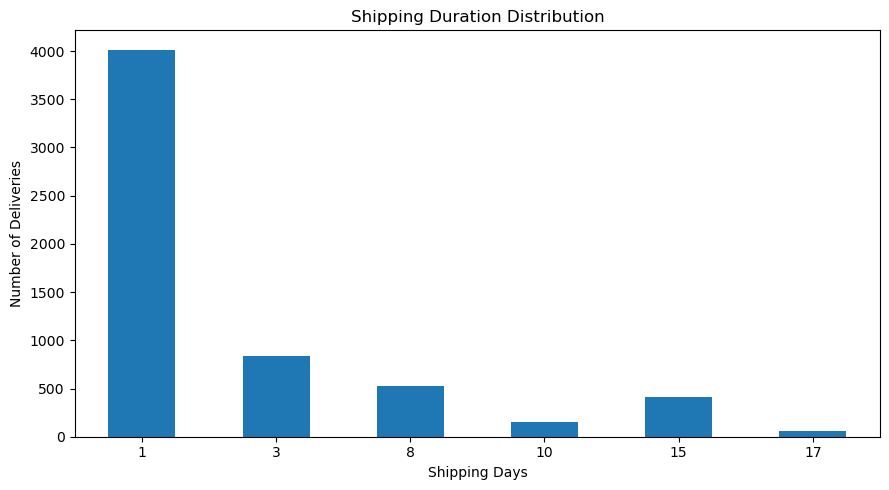

In [317]:
# Bar chart of shipping duration distribution



shipping_distribution.plot(
    kind="bar",
    figsize=(9, 5),
    title="Shipping Duration Distribution"
)

plt.xlabel("Shipping Days")
plt.ylabel("Number of Deliveries")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

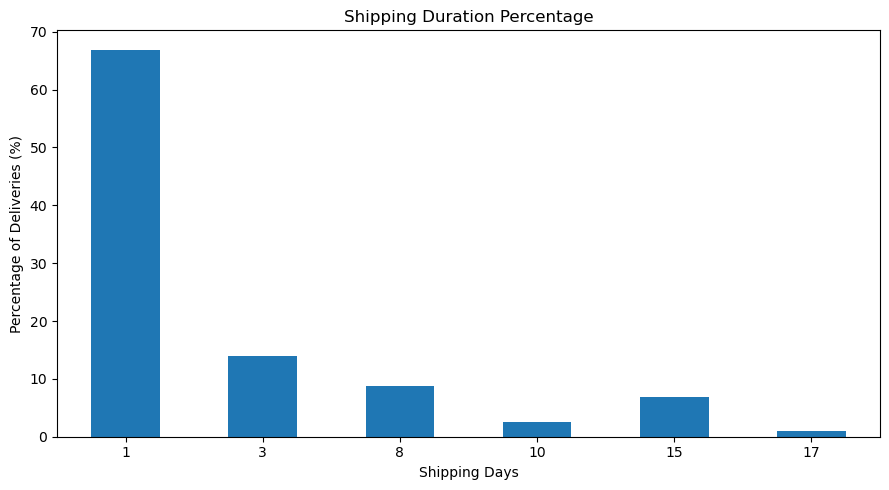

In [318]:
# Bar chart of shipping duration percentages

shipping_percentage.plot(
    kind="bar",
    figsize=(9, 5),
    title="Shipping Duration Percentage"
)

plt.xlabel("Shipping Days")
plt.ylabel("Percentage of Deliveries (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Key Business Insights – Shipping Performance

1. The average shipping duration is approximately 3.23 days across 6,000 deliveries.
2. The median shipping duration is 1 day, indicating that at least half of deliveries were completed within one day.
3. Approximately 66.90% of deliveries were completed within one day.
4. Approximately 80.88% of deliveries were completed within three days.
5. Around 19.12% of deliveries took eight days or longer.
6. The maximum shipping duration was 17 days, highlighting some unusually long delivery times.

**Business Recommendation:** Maintain the strong one-day delivery performance while investigating the causes of longer shipping durations. Monitor delayed deliveries and identify opportunities to improve delivery consistency.

## 12. Key Business Findings

This section summarizes the key findings obtained from financial performance, product category, customer segment, customer and product, and shipping performance analyses. The objective is to highlight important business patterns and identify opportunities for improving revenue, profitability, and operational efficiency.

### 1. Overall Financial Performance

- Total Revenue: 3,480,101.59
- Total Cost: 2,447,444.00
- Total Profit: 1,032,657.59
- Gross Profit Margin: 29.67%

The business generated a gross profit margin of 29.67%, indicating that approximately 29.67% of revenue remained after accounting for the recorded costs.

### 2. Category Performance

- Paper & Tissue generates the highest revenue but has the lowest profit margin (23.85%).
- Cleaning Supplies generates the highest total profit (323,713.47).
- Breakroom Supplies achieves the highest profit margin (40.65%) despite having the lowest revenue.
- Cleaning Supplies and Breakroom Supplies demonstrate stronger profitability margins.

**Key Takeaway:** High revenue does not necessarily mean high profitability. Product categories should be evaluated using both revenue and profit margin.

### 3. Customer Segment Performance

- Segment A generates the highest revenue (3,178,602.69) and profit (935,131.69).
- Segment D has the highest profit margin (44.56%) despite generating the lowest revenue.
- Segment B achieves a profit margin of 35.05%.
- Segment C has the lowest profit margin (29.26%).

**Key Takeaway:** Segment A is the largest contributor to business performance, while smaller segments demonstrate different profitability levels.

### 4. Customer Performance

- Sleek Maintainers of Bayfield is the highest revenue-generating customer, contributing 414,407.58 in revenue.
- This customer also generates the highest total profit among the customers analyzed (127,706.58).
- Gleaming Sanitizers of Canyonport ranks second in revenue, generating 253,853.69.
- Customer-level analysis helps identify valuable accounts and opportunities for customer retention.

**Key Takeaway:** Maintaining relationships with high-value customers is important for sustaining business revenue and profitability.

### 5. Product Performance

- Pristine Disinfectant Wipes generates the highest revenue among the top 10 products (223,056.76).
- It also generates the highest profit among these products (74,936.76).
- Radiant Glossy Photo Paper ranks second in revenue (147,721.36).
- Immaculate Air Freshener generates 33,111.58 in profit.

**Key Takeaway:** Identifying high-revenue and high-profit products helps businesses make better inventory, pricing, and sales decisions.

### 6. Shipping Performance

- Average shipping duration is approximately 3.23 days.
- Median shipping duration is 1 day.
- Approximately 66.90% of deliveries are completed within one day.
- Approximately 80.88% of deliveries are completed within three days.
- Around 19.12% of deliveries take eight days or longer.
- The maximum recorded shipping duration is 17 days.

**Key Takeaway:** Most deliveries are completed quickly, but longer delivery durations indicate opportunities to improve shipping consistency.

## 13. Business Recommendations

Based on the financial, category, customer, product, and shipping performance analysis, the following recommendations can help improve business profitability, strengthen customer relationships, and enhance operational efficiency.

### 1. Improve Category Profitability

- Review the pricing and cost structure of Paper & Tissue, which has the lowest profit margin (23.85%).
- Maintain the profitability of Cleaning Supplies, which generates the highest total profit.
- Explore opportunities to increase Breakroom Supplies sales while maintaining its strong profit margin.

### 2. Strengthen Customer Relationships

- Focus on retaining high-revenue customers, particularly Sleek Maintainers of Bayfield.
- Investigate opportunities to grow smaller customer segments.
- Monitor customer-level revenue and profitability to identify valuable accounts.

### 3. Optimize Product Performance

- Maintain the sales performance of high-contributing products such as Pristine Disinfectant Wipes.
- Evaluate product costs and margins to identify opportunities for profitability improvements.
- Use product performance data to support inventory and sales planning.

### 4. Improve Shipping Efficiency

- Investigate deliveries taking 8 days or longer.
- Monitor average shipping duration and delivery distribution regularly.
- Identify opportunities to improve delivery consistency and reduce unusually long shipping times.

### 5. Establish Continuous Performance Monitoring

- Track revenue, cost, profit, and gross profit margin regularly.
- Use Power BI dashboards to monitor category, customer, and product performance.
- Review KPIs periodically to support data-driven business decisions.

## 14. Conclusion



This project analyzed a synthetic B2B financial dataset containing 6,000 invoice records to evaluate overall business performance, profitability, customer contribution, product performance, and shipping efficiency.

Using Python and Pandas, the dataset was explored, validated, cleaned, and analyzed. SQL was used to perform business queries and calculate key performance indicators, while Power BI was used to create an interactive financial performance dashboard.

The analysis produced several important findings:

- The business generated total revenue of 3,480,101.59 and total profit of 1,032,657.59, with a gross profit margin of 29.67%.
- Cleaning Supplies generated the highest total profit among product categories.
- Segment A contributed the highest revenue and total profit.
- Sleek Maintainers of Bayfield was the highest revenue-generating customer.
- Pristine Disinfectant Wipes was the highest revenue-generating product among the top 10 products analyzed.
- Average shipping duration was approximately 3.23 days.

The project demonstrates how data analysis tools can transform raw transactional data into meaningful business insights. The findings and recommendations can help support decisions related to pricing, profitability, customer retention, product performance, and shipping efficiency.

Overall, this project provided practical experience in data cleaning, exploratory data analysis, SQL querying, KPI development, and business intelligence reporting.

In [319]:
print("TOTAL REVENUE:", df["revenue"].sum())
print("TOTAL COST:", df["cost"].sum())
print("TOTAL PROFIT:", df["margin"].sum())

profit_margin = (df["margin"].sum() / df["revenue"].sum()) * 100
print("PROFIT MARGIN:", round(profit_margin, 2), "%")

print("TOTAL RECORDS:", len(df))

TOTAL REVENUE: 3480101.59
TOTAL COST: 2447444
TOTAL PROFIT: 1032657.5899999999
PROFIT MARGIN: 29.67 %
TOTAL RECORDS: 6000
